In [1]:
import numpy as np

RADIUS = 0.5

target = 0.7778 # From original LSMC paper
density = target * np.sqrt(2) # From original LSMC paper, eq 7

# Calculate packing fraction
eta = density * (4/3) * np.pi * RADIUS**3

print(eta)

0.5759457248832629


In [15]:
def calculate_free_energy(visit_counts, bias_weights, bias_off):
    counts = np.array(visit_counts, dtype=np.float64, copy=True)
    biases = np.array(bias_weights, dtype=np.float64, copy=True)
    
    ln_g = np.log(counts) + biases
    
    def log_sum_exp_safe(log_arr):
        x_max = np.max(log_arr)
        return x_max + np.log(np.sum(np.exp(log_arr - x_max)))
    
    # Calculate log(Z) directly to avoid underflow/overflow issues
    log_Z_fcc = log_sum_exp_safe(ln_g[:bias_off])
    log_Z_hcp = log_sum_exp_safe(ln_g[bias_off + 1:])
    
    # delta_F = -ln(Z_hcp / Z_fcc)
    delta_F = -(log_Z_hcp - log_Z_fcc)

    return delta_F

Creating LSMCEngine with overlaps from -100 to 100
ln(f) converged to 1.0000000000 at 23000 sweeps.
Current Delta F: 0.02778 Kb*T | Elapsed: 0.8s
ln(f) converged to 0.5000000000 at 36000 sweeps.
Current Delta F: -7.41094 Kb*T | Elapsed: 1.2s
ln(f) converged to 0.2500000000 at 78000 sweeps.
Current Delta F: 5.42704 Kb*T | Elapsed: 2.5s
ln(f) converged to 0.1250000000 at 119000 sweeps.
Current Delta F: 0.37847 Kb*T | Elapsed: 3.6s
ln(f) converged to 0.0625000000 at 159000 sweeps.
Current Delta F: 0.13065 Kb*T | Elapsed: 4.9s
ln(f) converged to 0.0312500000 at 186000 sweeps.
Current Delta F: 0.34349 Kb*T | Elapsed: 5.7s
ln(f) converged to 0.0156250000 at 214000 sweeps.
Current Delta F: 0.60051 Kb*T | Elapsed: 6.5s
ln(f) converged to 0.0078125000 at 260000 sweeps.
Current Delta F: 0.35919 Kb*T | Elapsed: 7.8s
ln(f) converged to 0.0039062500 at 322000 sweeps.
Current Delta F: 0.00713 Kb*T | Elapsed: 9.8s
ln(f) converged to 0.0019531250 at 350000 sweeps.
Current Delta F: -0.00448 Kb*T | Elap

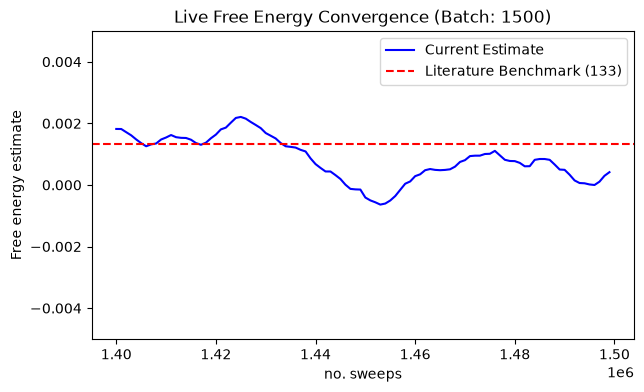

ln(f) converged to 0.0000076294 at 1913000 sweeps.
Current Delta F: 0.00068 Kb*T | Elapsed: 57.4s


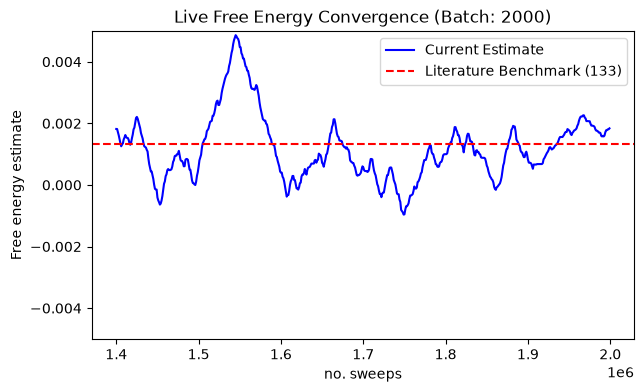

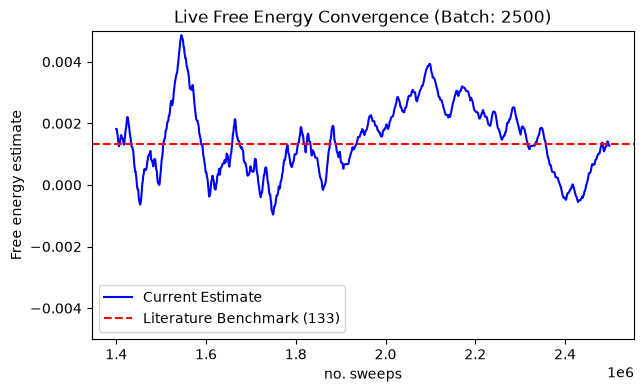

ln(f) converged to 0.0000038147 at 2507000 sweeps.
Current Delta F: 0.00123 Kb*T | Elapsed: 75.2s
ln(f) converged to 0.0000019073 at 2885000 sweeps.
Current Delta F: 0.00050 Kb*T | Elapsed: 86.6s


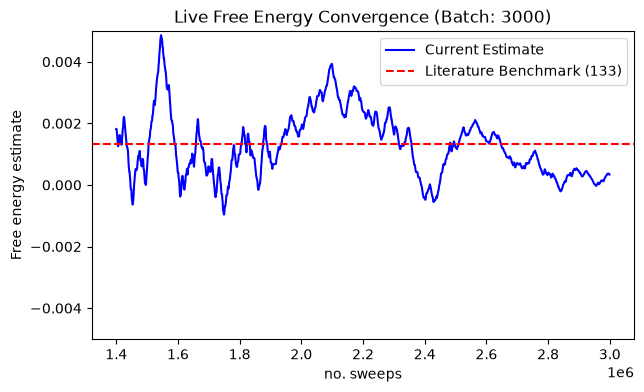

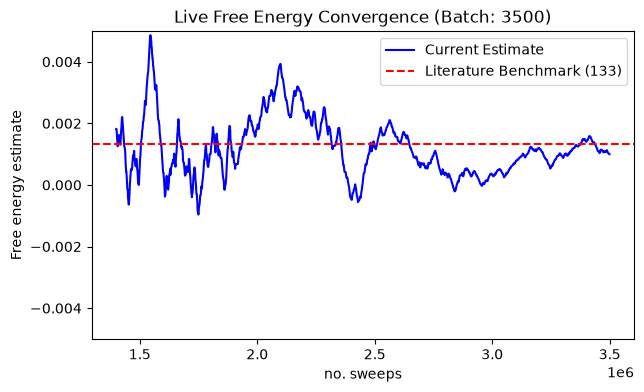

ln(f) converged to 0.0000009537 at 3533000 sweeps.
Current Delta F: 0.00070 Kb*T | Elapsed: 105.7s


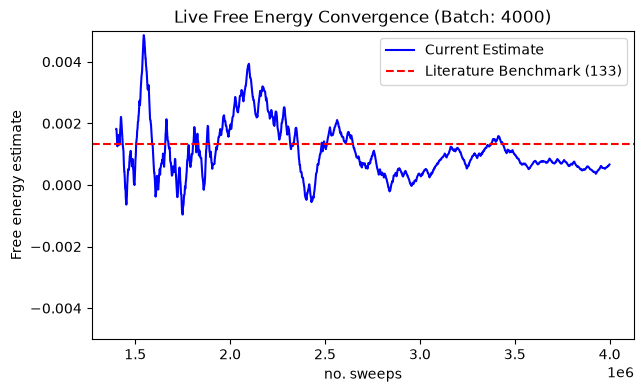

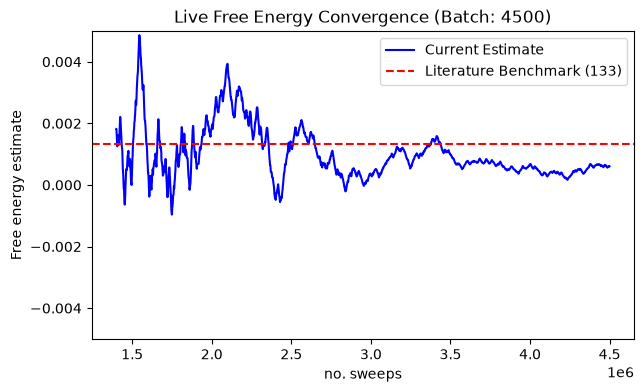

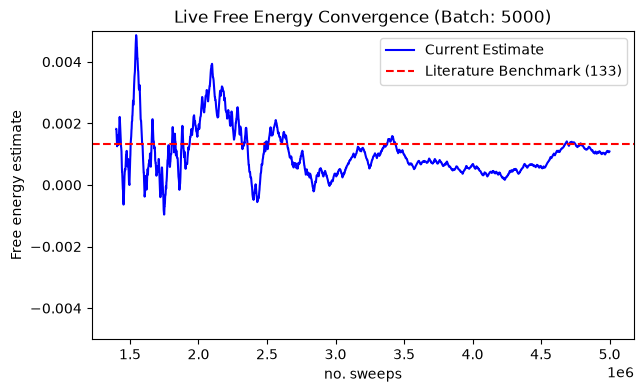

In [47]:
import time
import matplotlib.pyplot as plt
from hpmc.utils.lattice import generate_lattice
import hpmc

fcc_lattice = generate_lattice(eta, RADIUS, "fcc", 6, 6, 6)
hcp_lattice = generate_lattice(eta, RADIUS, "hcp", 6, 6, 6)

fcc = hpmc.State(hpmc.ParticleType.Sphere, fcc_lattice[3], radius=RADIUS)
hcp = hpmc.State(hpmc.ParticleType.Sphere, hcp_lattice[3], radius=RADIUS)

fcc.set_coords(*fcc_lattice[:3])
hcp.set_coords(*hcp_lattice[:3])

assert fcc.n_particles() == hcp.n_particles()

N = fcc.n_particles()

min_M = -100
max_M = 100
bias_off = -min_M

print(f"Creating LSMCEngine with overlaps from {min_M} to {max_M}")

lsmc = hpmc.LSMCEngine(fcc, hcp, min_M, max_M, seed=12345678)
lsmc.wl_ln_f = 1.0
total_visit_counts = np.zeros_like(lsmc.visit_counts, dtype=np.uint64)

SWEEPS = 1_000
BATCHES = 5_000
START_PLOT = 1400
LN_F_TOLERANCE = 1e-7

delta_F_history = []

start = time.perf_counter()
for i in range(BATCHES):
    lsmc.run_batch(sweeps=SWEEPS, max_disp=0.1)

    delta_F = 0
    if np.min(total_visit_counts + lsmc.visit_counts) > 0:
        delta_F = calculate_free_energy(total_visit_counts + lsmc.visit_counts, lsmc.bias_weights, bias_off) / N
    delta_F_history.append(delta_F)

    if i > START_PLOT and (i + 1) % 500 == 0:
        fig, ax = plt.subplots(figsize=(7, 4))
        # Clear the plot axis and redraw
        ax.plot(
            np.arange(START_PLOT * SWEEPS, (i + 1) * SWEEPS, SWEEPS),
            delta_F_history[START_PLOT:],
            color='blue',
            label='Current Estimate'
        )
        ax.axhline(y=0.00133, color='red', linestyle='--', label='Literature Benchmark (133)')
        ax.set_ylim(-0.005, 0.005)
        ax.set_title(f"Live Free Energy Convergence (Batch: {i + 1})")
        ax.set_xlabel("no. sweeps")
        ax.set_ylabel("Free energy estimate")
        ax.legend()

        plt.show()

    # Pull the latest counts from the C++ layer
    counts = lsmc.visit_counts

    min_val = np.min(counts)
    avg_val = np.mean(counts)
    max_val = np.max(counts)

    # 1. Ensure all accessible bins have been touched at least once
    if min_val > 0:
        # 2. Check for the overall flatness
        if (min_val > 0.8 * avg_val) and (max_val < 1.2 * avg_val):
            elapsed = time.perf_counter() - start

            print(f"ln(f) converged to {lsmc.wl_ln_f:.10f} at {(i+1)*SWEEPS} sweeps.")
            print(f"Current Delta F: {delta_F:.5f} Kb*T | Elapsed: {elapsed:.1f}s")

            lsmc.wl_ln_f /= 2
            total_visit_counts += lsmc.visit_counts
            lsmc.reset_visit_counts()

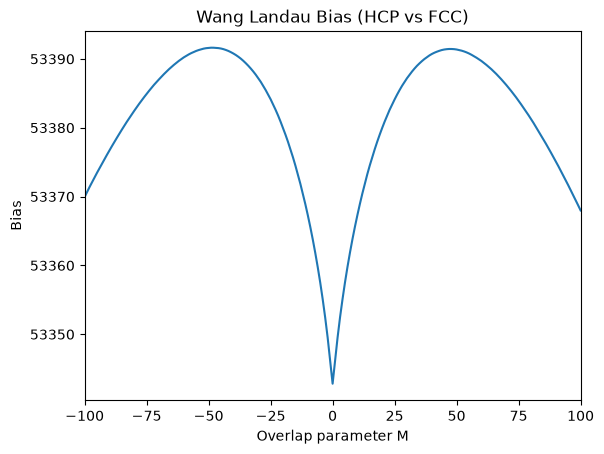

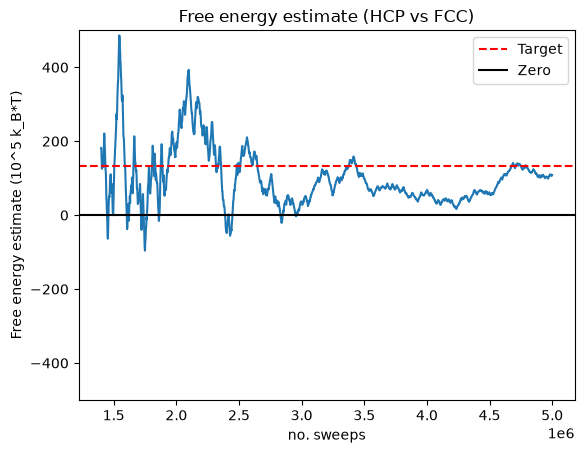

The free energy difference (ΔF_HCP-FCC) is: 0.0009590473 k_B*T


In [48]:
import matplotlib.pyplot as plt

m_axis = np.arange(min_M, max_M + 1, dtype=np.int32)
plt.xlim(min_M, max_M)

plt.plot(m_axis, lsmc.bias_weights)
plt.title("Wang Landau Bias (HCP vs FCC)")
plt.xlabel("Overlap parameter M")
plt.ylabel("Bias")
plt.show()

plt.plot(
    np.arange(START_PLOT * SWEEPS, (i + 1) * SWEEPS, SWEEPS),
    np.array(delta_F_history)[START_PLOT:] * 10**5
)
plt.ylim(-500, 500)
plt.axhline(y=132, color='red', linestyle='--', linewidth=1.5, label='Target')
plt.axhline(y=0.0, color='black', linestyle='-', linewidth=1.5, label='Zero')
plt.title("Free energy estimate (HCP vs FCC)")
plt.xlabel("no. sweeps")
plt.ylabel("Free energy estimate (10^5 k_B*T)")
plt.legend()
plt.show()

delta_F = calculate_free_energy(total_visit_counts, lsmc.bias_weights, bias_off) / N
print(f"The free energy difference (ΔF_HCP-FCC) is: {delta_F:.10f} k_B*T")

In [23]:
# import numpy as np

# np.save("total_visit_counts.npy", total_visit_counts)
# np.save("bias_weights.npy", lsmc.bias_weights)
# np.save("delta_F_history.npy", np.array(delta_F_history))